# 96장 · 출처 표기 함수와 응답 카드

출처 표기는 읽는 사람이 원문으로 돌아갈 만큼 구체적이어야 합니다. 문서 ID 외에 원문의 위치를 조합해 답변 카드에 표시합니다.

검색 함수가 규정을 돌려주면 점검 담당자는 그것을 읽고 원문을 찾아야 합니다. Q01에서 사용자에게 보일 두 줄을 직접 조립한 뒤, 장비명이 없는 경우에는 어떻게 화면이 달라져야 할지 정합니다.

실행을 확인한 커널은 Python 3.12.15입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요. 팀별 변형을 시도한 뒤 해당 셀 아래에서 예시를 펼쳐 비교할 수 있습니다.


## citation_line()으로 원문 위치 표시

첫 수용 사례　질문 “장비 A의 점검 전 확인 사항은?” / 답 “점검 전 전원 표시등을 확인합니다.” / 근거 RULE-A, 가상 장비실 규정 A, 1쪽 2.1절, 2026-11-01, rules-v1. 응답 데이터를 그대로 보여 주면 어느 숫자가 페이지인지 알기 어렵습니다. 화면 문장에 단위를 붙이되 문서의 실제 값은 바꾸지 않습니다.


### 셀 01 · citation_line()의 위치 표기

로컬 규칙 Q01의 저장 응답을 읽어 출처를 화면용 문자열로 만듭니다.


In [1]:
reply = {'status': 'answered',
 'answer': '점검 전 전원 표시등을 확인합니다.',
 'sources': [{'id': 'RULE-A',
              'text': '점검 전 전원 표시등을 확인합니다.',
              'source': '가상 장비실 규정 A',
              'page': 1,
              'section': '2.1',
              'revised_on': '2026-11-01',
              'version': 'rules-v1'}],
 'mode': 'local_rule_fixture',
 'model_calls': 0}
def citation_line(source):
    return (f"{source['id']} | {source['source']} | p.{source['page']} | "
            f"{source['section']}절 | 개정일 {source['revised_on']} | {source['version']}")

def show_reply(response):
    print(response["answer"])
    for source in response["sources"]:
        print(citation_line(source))

show_reply(reply)

점검 전 전원 표시등을 확인합니다.
RULE-A | 가상 장비실 규정 A | p.1 | 2.1절 | 개정일 2026-11-01 | rules-v1


답 바로 아래에 RULE-A의 위치가 붙습니다. 출처 ID만 나왔다면 검색 결과의 누락인지 화면 함수에서 일부 필드만 읽었는지 두 값을 대조하세요.


### 출처가 0건이면 show_reply()에서 어느 줄까지 실행될까?

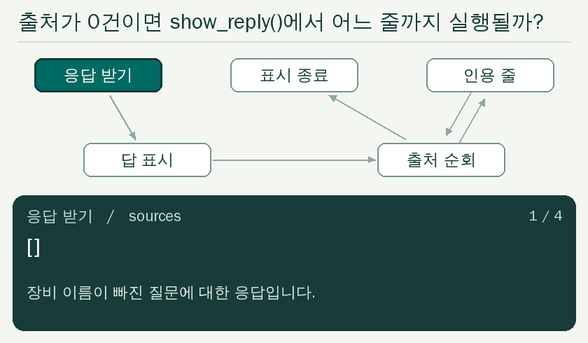

추가 질문도 답변 영역에 표시됩니다. 빈 sources를 순회하면 citation_line()은 한 번도 호출되지 않습니다.


### show_reply()의 추가 질문

아래 셀을 실행한 뒤 바로 앞의 결과와 비교하세요.


In [2]:
reply_missing = {"answer": "장비 A인가요, 장비 B인가요?", "sources": []}
show_reply(reply_missing)

장비 A인가요, 장비 B인가요?


출처가 비어 있어서 안내 문장 한 줄만 나옵니다. 앞 질문의 RULE-A를 다시 표시하지 않습니다.


## show_reply()의 추가 질문 분기

Q02의 완료 예시　상태 need_clarification / 문구 “장비 A 또는 장비 B 중 하나를 지정하세요.” / 출처 없음. 출처가 항상 한 건이라고 가정하고 목록의 첫 항목을 읽으면 이 화면에서는 오류가 납니다. 답변 영역은 먼저 상태를 읽고, 출처가 있을 때만 원문 위치를 그립니다.


### 과제 02 · 선택 연습 · 출처 카드 변형

팀이 장비 B를 맡았다고 보고 같은 화면 함수로 두 번째 규정의 위치를 표시하세요.

같은 표시 함수를 장비를 지정하지 않은 Q02에도 사용해 보세요. sources가 비면 첫 출처를 꺼내지 않고 되묻는 문장만 출력합니다.


In [3]:
reply_b = {'status': 'answered',
 'answer': '점검 전 고정 장치를 확인합니다.',
 'sources': [{'id': 'RULE-B',
              'text': '점검 전 고정 장치를 확인합니다.',
              'source': '가상 장비실 규정 B',
              'page': 2,
              'section': '2.2',
              'revised_on': '2026-11-01',
              'version': 'rules-v1'}],
 'mode': 'local_rule_fixture',
 'model_calls': 0}
# reply_b의 답과 근거 줄을 표시하세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>reply_b = {&#x27;status&#x27;: &#x27;answered&#x27;,
 &#x27;answer&#x27;: &#x27;점검 전 고정 장치를 확인합니다.&#x27;,
 &#x27;sources&#x27;: [{&#x27;id&#x27;: &#x27;RULE-B&#x27;,
              &#x27;text&#x27;: &#x27;점검 전 고정 장치를 확인합니다.&#x27;,
              &#x27;source&#x27;: &#x27;가상 장비실 규정 B&#x27;,
              &#x27;page&#x27;: 2,
              &#x27;section&#x27;: &#x27;2.2&#x27;,
              &#x27;revised_on&#x27;: &#x27;2026-11-01&#x27;,
              &#x27;version&#x27;: &#x27;rules-v1&#x27;}],
 &#x27;mode&#x27;: &#x27;local_rule_fixture&#x27;,
 &#x27;model_calls&#x27;: 0}
print(reply_b[&quot;answer&quot;])
print(citation_line(reply_b[&quot;sources&quot;][0]))</code></pre>
<p>실행 결과</p><pre><code>점검 전 고정 장치를 확인합니다.
RULE-B | 가상 장비실 규정 B | p.2 | 2.2절 | 개정일 2026-11-01 | rules-v1</code></pre>
<p>고정 장치, RULE-B, 2쪽 2.2절로 바뀝니다. A의 페이지나 절이 그대로면 화면에 적힌 고정 문구부터 찾으세요.</p>
</details>


## 돌아보기

Q01의 답과 원문 위치, Q02에서 다시 묻는 문장을 97장에 넘기세요. 화면 시안의 출처를 보고 다른 사람이 실제 절을 찾을 수 있는지는 별도 관찰 항목입니다.
